# Hälsostudie – Statistisk Dataanalys

**Individuell inlämningsuppgift – Del 2**

## Inledning och syfte

Syftet med denna analys är att undersöka ett dataset från en hälsostudie med hjälp av Python och statistiska metoder.

Datasetet innehåller 800 observationer och information om deltagarnas ålder, kön, längd, vikt, systoliska blodtryck, kolesterolnivå, rökvanor och förekomst av en viss sjukdom.

Analysen omfattar datakvalitetskontroll, beskrivande statistik, datavisualisering, simulering av sjukdomsförekomst, konfidensintervall, hypotesprövning samt linjär regression.

Ett särskilt syfte är att undersöka om rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare. Dessutom undersöks sambandet mellan ålder och systoliskt blodtryck med hjälp av linjär regression.

Analysen genomförs i Jupyter Notebook med hjälp av Python och biblioteken Pandas, NumPy, Matplotlib och SciPy.

I Del 2 har koden vidareutvecklats och strukturerats genom att delar av beräkningarna har flyttats till återanvändbara funktioner och moduler samt genom att klassen HealthAnalyzer har skapats. Den linjära regressionsanalysen har genomförts med NumPy för att tillämpa linjär algebra i praktiken.

In [1]:
# Import av bibliotek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import sys
from pathlib import Path

# Sökväg till projektets egna moduler
sys.path.insert(0, str(Path.cwd().parent / "src"))

# Import av funktioner från health_utils
from health_utils import (
    berakna_rokarandel,
    simulera_sjukdom,
    berakna_konfidensintervall,
    hypotesprovning_blodtryck,
    berakna_linjar_regression,
    berakna_r2
)

# Import av klassen HealthAnalyzer
from health_analyzer import HealthAnalyzer


## Datainläsning och Översikt

Datasetet läses in från CSV-filen med hjälp av Pandas. Ett analysobjekt skapas med klassen HealthAnalyzer för att kunna utföra olika analyser av datasetet.

De fem första observationerna visas för att ge en överblick över variablerna och datamaterialets struktur.

In [2]:
# Inläsning av datasetet
df = pd.read_csv("../data/health_study_dataset.csv")

# Skapa ett analysobjekt för hälsodatasetet
analys = HealthAnalyzer(df)

# Visa de fem första observationerna
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## Datakvalitetskontroll

Innan den statistiska analysen påbörjas kontrolleras datasetet
med avseende på saknade värden, dubbletter och eventuella
avvikande värden. Syftet är att säkerställa att datamaterialet
är lämpligt för vidare analys.

In [3]:

# Antal observationer, kolumner, datatyper och saknade värden
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [4]:
# Kontroll av saknade värden
df.isna().sum()

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

In [5]:
# Kontroll av dubbletter och unika ID
print("Antal identiska rader:", df.duplicated().sum())
print("Är alla ID unika?", df["id"].is_unique)

Antal identiska rader: 0
Är alla ID unika? True


In [6]:
# Översikt av grundläggande statistik
df.describe()

,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


In [7]:
# Kontroll av kategoriska variabler
print(df["sex"].value_counts())
print(df["smoker"].value_counts())
print(df["disease"].value_counts())

sex
F    403
M    397
Name: count, dtype: int64
smoker
No     587
Yes    213
Name: count, dtype: int64
disease
0    753
1     47
Name: count, dtype: int64


**Sammanfattning av datakvalitetskontrollen**

Datasetet innehåller 800 observationer och 9 variabler. Inga saknade värden eller dubbletter har identifierats och samtliga deltagar-ID är unika. De numeriska och kategoriska variablerna har kontrollerats utan att några uppenbara felaktigheter upptäckts.

Slutsats: Datamaterialet bedöms vara lämpligt för fortsatt analys utan ytterligare datarensning.

## 1. Beskrivande Statistik

Syftet med analysen är att få en övergripande bild av deltagarnas ålder, vikt, längd, systoliska blodtryck och kolesterolnivå.

För varje variabel beräknas medelvärde, median, minimivärde och maximivärde. Dessa mått används för att beskriva datamaterialets centrala värden och variation.

In [8]:
# Variabler som ingår i analysen
variabler = ["age", "weight", "height", "systolic_bp", "cholesterol"]

# Beräkning av beskrivande statistik med klassen HealthAnalyzer
analys.berakna_statistik(variabler)

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


**Tolkning av beskrivande statistik**

Resultaten visar att medelvärde och median ligger relativt nära varandra för samtliga fem variabler. Detta kan tyda på att fördelningarna inte är kraftigt snedfördelade, men för att bedöma fördelningarnas form krävs ytterligare analys, exempelvis med histogram.

Vikten varierar mellan 33,7 och 114,4 kg. Det låga minimivärdet är värt att uppmärksamma, men kan inte bedömas som felaktigt utan ytterligare information.

Det genomsnittliga systoliska blodtrycket är cirka 149 mmHg, vilket är en intressant observation inför den fortsatta analysen av eventuella skillnader mellan rökare och icke-rökare.

## 2. Datavisualisering

För att undersöka hälsodatans fördelning och eventuella skillnader mellan deltagargrupper används tre olika diagram: histogram, boxplot och stapeldiagram.

**2.1 Fördelning av systoliskt blodtryck**

Histogrammet visar hur deltagarnas systoliska blodtryck är fördelat. Syftet är att undersöka fördelningens form, spridning och eventuella avvikande värden.

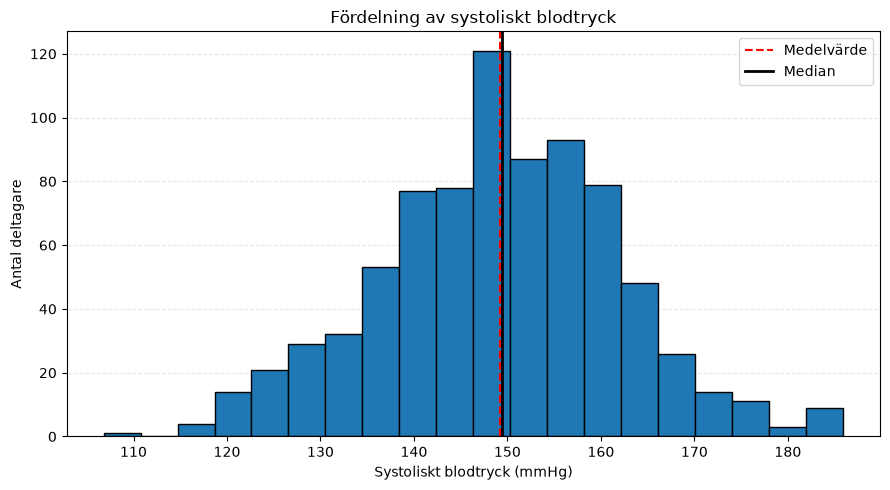

In [9]:
# Histogram över systoliskt blodtryck
plt.figure(figsize=(9, 5))

plt.hist(df["systolic_bp"], bins=20, edgecolor="black")

# Markering av medelvärde och median
plt.axvline(df["systolic_bp"].mean(), color="red",
            linestyle="--", label="Medelvärde")

plt.axvline(df["systolic_bp"].median(), color="black",
            linestyle="-", linewidth=2, label="Median")

plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal deltagare")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.legend()
plt.tight_layout()
plt.show()

**Tolkning av histogrammet**

Histogrammet visar att det systoliska blodtrycket har en ungefär klockformad och relativt symmetrisk fördelning. Flest deltagare återfinns kring 145–160 mmHg, medan antalet observationer minskar mot de lägre och högre blodtrycksvärdena.

Detta överensstämmer med att medelvärdet (149,18 mmHg) och medianen (149,40 mmHg) ligger nära varandra.

Fördelningen liknar en normalfördelning, men histogrammet är inte tillräckligt för att fastställa normalfördelning statistiskt.

**2.2 Viktfördelning efter kön**

Ett lådagram används för att jämföra viktfördelningen mellan kvinnor och män. Diagrammet visar median, kvartiler, spridning och eventuella avvikande värden inom respektive grupp.

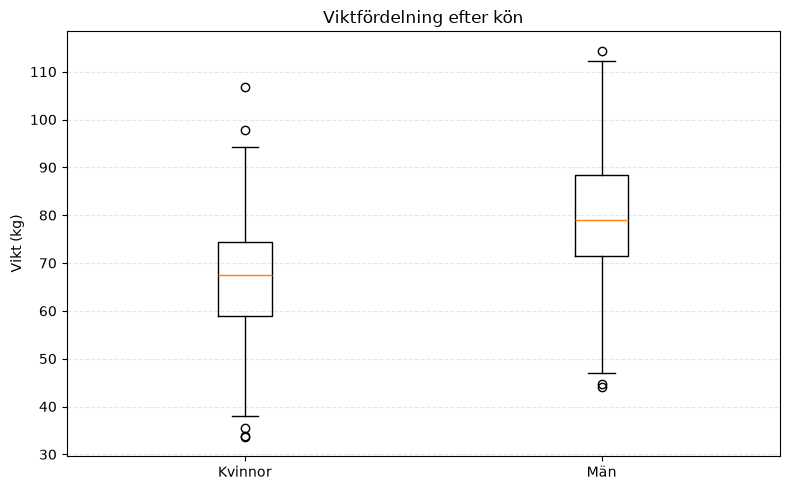

In [10]:
# Uppdelning av vikt efter kön
vikt_kvinnor = df[df["sex"] == "F"]["weight"]
vikt_man = df[df["sex"] == "M"]["weight"]

# Boxplot över viktfördelning efter kön
plt.figure(figsize=(8, 5))

plt.boxplot([vikt_kvinnor, vikt_man], tick_labels=["Kvinnor", "Män"])

plt.title("Viktfördelning efter kön")
plt.ylabel("Vikt (kg)")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

**Tolkning av viktfördelningen**

Boxploten visar att männen generellt har högre vikt än kvinnorna i det undersökta datamaterialet, med en median på ungefär 79 kg jämfört med cirka 68 kg för kvinnorna.

Båda grupperna uppvisar en relativt stor spridning i vikt, och det förekommer några avvikande värden både bland kvinnor och män. Dessa värden behöver inte vara felaktiga, utan representerar observationer som ligger utanför boxplotens normala visare.

Diagrammet beskriver skillnader i viktfördelning mellan grupperna, men visar inte om skillnaden är statistiskt signifikant.

**2.3 Andel rökare och icke-rökare**

Stapeldiagrammet visar den procentuella fördelningen mellan rökare och icke-rökare i hälsostudien. Syftet är att tydliggöra hur stor andel av deltagarna som tillhör respektive grupp.

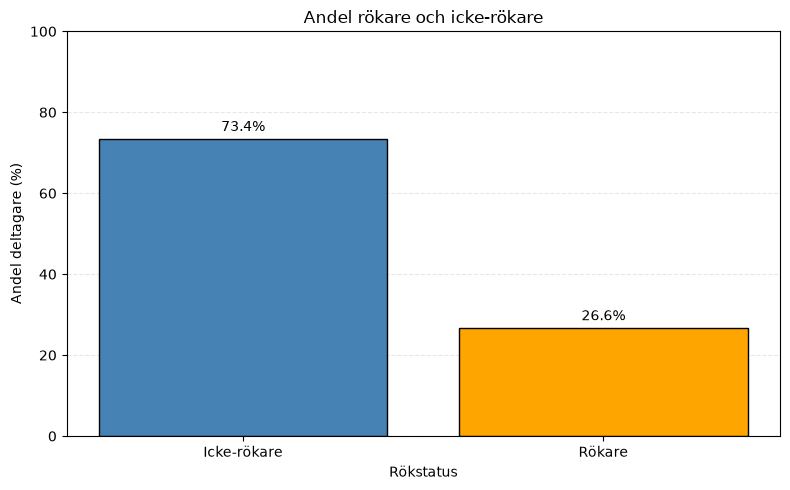

In [11]:
# Beräkning av procentuell andel rökare och icke-rökare
andel_rokare = berakna_rokarandel(df)

# Stapeldiagram över andel rökare och icke-rökare
plt.figure(figsize=(8, 5))

plt.bar(["Icke-rökare", "Rökare"],
        [andel_rokare["No"], andel_rokare["Yes"]],
        color=["steelblue", "orange"],
        edgecolor="black")

plt.title("Andel rökare och icke-rökare")
plt.xlabel("Rökstatus")
plt.ylabel("Andel deltagare (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

# Procenttal ovanför staplarna
for i, andel in enumerate([andel_rokare["No"], andel_rokare["Yes"]]):
    plt.text(i, andel + 2, f"{andel:.1f}%", ha="center")

plt.tight_layout()
plt.show()

**Tolkning av stapeldiagrammet**

Diagrammet visar att majoriteten av deltagarna är icke-rökare (73,4 %), medan 26,6 % är rökare. Icke-rökarna utgör därmed nästan tre gånger så stor andel som rökarna.

Fördelningen är relevant för den fortsatta analysen, där vi ska undersöka om det finns skillnader i systoliskt blodtryck mellan rökare och icke-rökare.

## 3. Simulering av Sjukdomsförekomst

Syftet är att undersöka hur slumpmässig variation kan påverka andelen personer med en viss sjukdom.

Först beräknas sjukdomsförekomsten i det ursprungliga datasetet. Därefter simuleras 1 000 personer med samma sannolikhet för sjukdom med hjälp av NumPy. Den simulerade andelen jämförs sedan med den observerade andelen.

Simuleringen använder ett fast slumpfrö för att resultatet ska kunna återskapas.

In [12]:
# Beräkning av sjukdomsandel i datasetet med klassens metod
andel_sjukdom = analys.berakna_sjukdomsandel()

print(f"Observerad andel med sjukdom: {andel_sjukdom:.2%}")

# Simulering av 1000 personer och beräkning av sjukdomsandelen
andel_simulerad = simulera_sjukdom(andel_sjukdom)

print(f"Simulerad andel med sjukdom: {andel_simulerad:.2%}")

# Jämförelse mellan observerad och simulerad sjukdomsförekomst
print(f"Skillnad: {(andel_simulerad - andel_sjukdom) * 100:.2f} procentenheter")


Observerad andel med sjukdom: 5.88%
Simulerad andel med sjukdom: 6.60%
Skillnad: 0.73 procentenheter


**Tolkning av simuleringen**

I det ursprungliga datasetet har 5,88 % av deltagarna sjukdomen. Vid simulering av 1 000 personer med samma sannolikhet blev andelen 6,6 %, vilket är 0,73 procentenheter högre.

Skillnaden kan förklaras av slumpmässig variation. Resultatet visar att även när sannolikheten är densamma kan utfallet skilja sig mellan olika urval.

## 4. Konfidensintervall för Systoliskt Blodtryck

Syftet är att uppskatta det genomsnittliga systoliska blodtrycket i den population som studiedeltagarna representerar.

Ett 95-procentigt konfidensintervall beräknas med hjälp av normalapproximation, baserat på stickprovets medelvärde, standardavvikelse och standardfel.

In [13]:
# Beräkning av 95 % konfidensintervall för systoliskt blodtryck med normalapproximation
medelvarde, standardavvikelse, standardfel, nedre_grans, ovre_grans = berakna_konfidensintervall(df)

# Statistiska mått för systoliskt blodtryck
print(f"Medelvärde: {medelvarde:.2f} mmHg")
print(f"Standardavvikelse: {standardavvikelse:.2f} mmHg")
print(f"Standardfel: {standardfel:.2f} mmHg")

# Resultat av konfidensintervallberäkningen
print(f"95 % konfidensintervall: [{nedre_grans:.2f}, {ovre_grans:.2f}] mmHg")

Medelvärde: 149.18 mmHg
Standardavvikelse: 12.79 mmHg
Standardfel: 0.45 mmHg
95 % konfidensintervall: [148.29, 150.07] mmHg


**Tolkning av konfidensintervallet**

Med hjälp av normalapproximation har ett 95-procentigt konfidensintervall för det genomsnittliga systoliska blodtrycket beräknats till ca 148,29–150,07 mmHg.

Medelvärdet är 149,18 mmHg och felmarginalen är ca ±0,89 mmHg. Den relativt lilla felmarginalen tyder på att medelvärdet är skattat med god precision.

Ett 95-procentigt konfidensintervall innebär att om undersökningen upprepades många gånger med nya slumpmässiga stickprov, skulle ungefär 95 % av de beräknade intervallen innehålla det verkliga populationsmedelvärdet.

## 5. Hypotesprövning – Blodtryck hos Rökare och Icke-Rökare

Syftet är att undersöka om rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare.

Hypoteserna formuleras enligt följande:

Nollhypotes (H₀): Rökare har inte högre genomsnittligt systoliskt blodtryck än icke-rökare.

Alternativ hypotes (H₁): Rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

Ett ensidigt Welch's t-test för två oberoende grupper används med signifikansnivån 5 % (α = 0,05). Testet förutsätter inte att grupperna har samma varians.

In [14]:
# Hypotesprövning med ensidigt Welch's t-test
medel_rokare, medel_icke_rokare, t_stat, p_varde = hypotesprovning_blodtryck(df)

# Medelblodtryck för respektive grupp
print(f"Medelblodtryck rökare: {medel_rokare:.2f} mmHg")
print(f"Medelblodtryck icke-rökare: {medel_icke_rokare:.2f} mmHg")

# Resultat av det ensidiga t-testet
print(f"t-statistik: {t_stat:.3f}")
print(f"p-värde: {p_varde:.4f}")

Medelblodtryck rökare: 149.52 mmHg
Medelblodtryck icke-rökare: 149.05 mmHg
t-statistik: 0.450
p-värde: 0.3264


**Tolkning av hypotesprövningen**

Resultatet visar att rökare har ett något högre genomsnittligt systoliskt blodtryck (149,52 mmHg) än icke-rökare (149,05 mmHg). Skillnaden är cirka 0,47 mmHg.

Ett ensidigt Welch's t-test genomfördes med signifikansnivån 5 %. Testet gav en t-statistik på 0,450 och ett p-värde på 0,3264.

P-värdet beskriver hur sannolikt det är att få ett minst lika extremt testresultat, givet att nollhypotesen är sann och testets antaganden gäller.

Eftersom p-värdet överstiger 0,05 kan nollhypotesen inte förkastas. Det finns därmed inte tillräckligt statistiskt stöd för att dra slutsatsen att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare i den population som studien avser.

Resultatet innebär inte att gruppernas verkliga medelvärden är identiska, utan att den observerade skillnaden inte är statistiskt signifikant.

# 6. Linjär Regression – Samband mellan Ålder och Systoliskt Blodtryck

Syftet är att undersöka om det finns ett linjärt samband mellan ålder och systoliskt blodtryck. Analysen genomförs med linjär regression och NumPy, där regressionskoefficienterna beräknas med hjälp av matriser, vektorer och minsta kvadratmetoden.

In [15]:
# Kopia av relevanta variabler för regressionsanalysen
df_regression = df[["age", "systolic_bp"]].copy()

# Översikt av de första observationerna
df_regression.head()

,age,systolic_bp
0,57,141.8
1,47,144.8
2,59,151.7
3,72,151.0
4,46,144.1


Intercept: 122.68 mmHg
Lutning: 0.54 mmHg per år
Förklaringsgrad (R²): 0.369
Förklarad variation: 36.9%


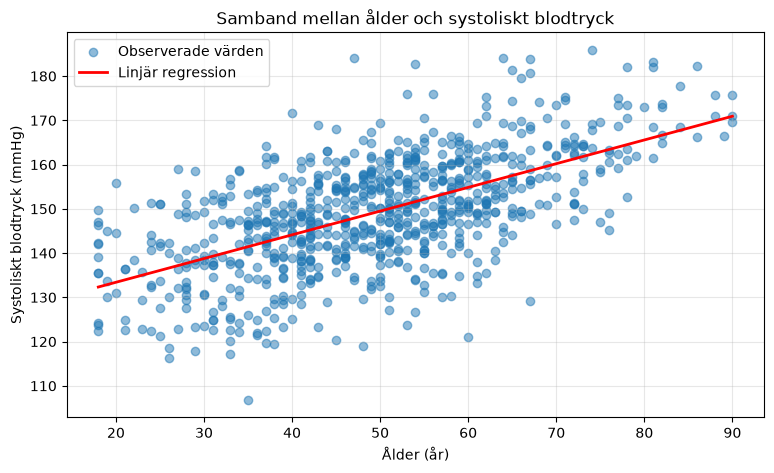

In [16]:
# Linjär regression mellan ålder och systoliskt blodtryck
intercept, lutning = berakna_linjar_regression(df_regression)

# Regressionskoefficienter
print(f"Intercept: {intercept:.2f} mmHg")
print(f"Lutning: {lutning:.2f} mmHg per år")

# Beräkning av förklaringsgraden R²
r2 = berakna_r2(df_regression, intercept, lutning)

print(f"Förklaringsgrad (R²): {r2:.3f}")
print(f"Förklarad variation: {r2:.1%}")

# Förutsagda blodtrycksvärden för regressionslinjen
x = np.linspace(df_regression["age"].min(), df_regression["age"].max(), 100)
y_pred = intercept + lutning * x

# Spridningsdiagram med observerade värden
plt.figure(figsize=(9, 5))

plt.scatter(
    df_regression["age"],
    df_regression["systolic_bp"],
    alpha=0.5,
    label="Observerade värden"
)

# Visualisering av regressionslinjen
plt.plot(x, y_pred, color="red", linewidth=2, label="Linjär regression")

plt.title("Samband mellan ålder och systoliskt blodtryck")
plt.xlabel("Ålder (år)")
plt.ylabel("Systoliskt blodtryck (mmHg)")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

Tolkning av den linjära regressionen

Spridningsdiagrammet visar ett positivt linjärt samband mellan ålder och systoliskt blodtryck.

Den linjära regressionsmodellen gav ett intercept på 122,68 mmHg och en lutning på 0,54 mmHg per år. Det innebär att det förutsagda systoliska blodtrycket ökar med cirka 0,54 mmHg för varje ytterligare års ålder. Interceptet motsvarar modellens förutsagda blodtryck vid 0 års ålder, men saknar praktisk betydelse här eftersom datasetet endast omfattar vuxna.

Den skattade regressionslinjen är:

$$
\hat{y} = 122,68 + 0,54 \cdot x
$$

där $\hat{y}$ är det förutsagda systoliska blodtrycket (mmHg) och $x$ är ålder i år.

Modellens förklaringsgrad är $R^2 = 0,369$, vilket innebär att cirka 36,9 % av variationen i systoliskt blodtryck förklaras av den linjära modellen med ålder som förklarande variabel. Resterande variation förklaras inte av modellen.

Resultatet visar ett positivt linjärt samband mellan ålder och systoliskt blodtryck, men innebär inte att ett orsakssamband har fastställts.

## Sammanfattning

Hälsostudien har analyserats med hjälp av beskrivande statistik, datavisualisering, simulering, konfidensintervall och hypotesprövning. Hypotesprövningen visade inte något statistiskt signifikant stöd för att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

I Del 2 har analysen kompletterats med linjär regression, som visade ett positivt samband mellan ålder och systoliskt blodtryck. Regressionsmodellen förklarade cirka 36,9 % av variationen i blodtrycket.

Koden har även vidareutvecklats genom att beräkningarna strukturerats i återanvändbara funktioner och moduler samt genom användning av klassen HealthAnalyzer. Detta har gjort koden mer strukturerad och lättare att återanvända.